# 11 · 손 전용 충돌 비용과 유효질량 — 이 프로젝트가 추가한 것

> 지도에 생긴 "모름" 구멍을 피하려고, 카메라가 본 손 점을 작은 장애물 조각으로 직접 넣는다. 손의 가정 질량으로 비용이 켜지는 거리 η를 정하고, 그 비용을 기존 비용에 더한다.

**지금 위치**

01~04 기초·MPC → 05~07 MPPI → 08~09 로봇팔 → 10 지도 → **11 손 비용** → 12 결과 → 13 Isaac Sim

**이 노트를 끝내면**
1. 손 관측점에서 대표점(anchor)을 뽑는 규칙을 실제 깊이 데이터로 재현할 수 있다.
2. 가정한 손 질량 → 환산질량 → η로 이어지는 정책을 계산하고, 그 의미와 한계를 설명할 수 있다.
3. 기존 비용에 손 비용을 더하는 방법과, cuRobo에 끼워 넣을 때 고정 크기 슬롯이 필요한 이유를 설명할 수 있다.

**필요한 것:** [02](02_cost_function.ipynb)의 "비용 = 항의 합", [05](05_mppi_core.ipynb)~[06](06_mppi_obstacles.ipynb)의 MPPI와 η 비용, [10](10_perception_map.ipynb)의 역투영과 "모름" 문제 · **예상 시간:** 45분

## 복습 퀴즈 (10)

<details><summary>1. 충돌 구가 손과 겹쳤는데 지도(nvblox) 비용이 0이었던 이유는?</summary>

비용은 구 중심 한 점의 거리값으로 계산한다. 구 중심이 깊이 미반환 영역이나 손바닥 뒤 가림 영역("모름")에 있어서 거리값이 sentinel(−100)이었고, 그 구의 비용은 0이 되었다.
</details>

<details><summary>2. 깊이 영상의 픽셀을 로봇 좌표 3D 점으로 바꾸려면 무엇이 필요한가?</summary>

픽셀 위치 (u, v), 그 픽셀의 깊이 z, 카메라 내부 파라미터 (fx, fy, cx, cy), 카메라가 로봇 기준으로 놓인 위치·방향 (R, t).
</details>

<details><summary>3. "모름" 칸과 "빈 칸"의 차이는?</summary>

빈 칸은 광선이 지나가서 비어 있다는 증거가 있는 칸이다. 모름 칸은 광선이 닿지 않아 아무 증거도 없는 칸이다. 모름 칸을 빈 칸처럼 다루면 안 된다.
</details>

In [1]:
import types
import numpy as np
from common import *
from course import point_rollout, point_cost, mppi_step, obstacle_gap, plot_scene_2d
import realdata as rd
plt = setup_plot()

## 1. 문제 — 지도만으로는 손 근처에서 실패했다

10 노트에서 본 Baseline(조건 **R**)의 실패를 다시 정리하면 이렇다.
- 로봇 구가 손 관측면과 겹친 7스텝(step 158~164) 동안 지도 비용이 0이었다.
- 원인은 구 **중심**이 지도의 "모름" 영역에 있었기 때문이다.

### 아이디어
구 중심의 지도 상태에 기대지 말고, **카메라가 실제로 본 손 표면 점들을 장애물로 직접 넣는다.** 그러면 구와 손 점 사이 거리를 바로 잴 수 있어서, 10 노트 5절의 "관측점 방식"처럼 겹침이 비용으로 드러난다.

여기에 한 가지를 더한다. 사람 손은 벽이나 테이블보다 더 조심해야 한다. 그래서 손에는 **별도의 η**(비용이 켜지는 거리)를 줄 수 있게 하고, 그 값을 손의 가정 질량으로 정한다(4절).

이 노트는 다음 순서로 진행한다.

```text
깊이 영상 → ROI 안의 손 점 → 20 mm 칸마다 대표점 → 1 mm 장애물 조각(최대 64개)
        → 질량으로 정한 η로 손 비용 계산 → 기존 비용에 더하기 → MPPI
```

## 2. 손 점만 고르기 — ROI

### 문제
깊이 영상에는 손 말고도 팔뚝, 배경 등이 찍힌다. 손에만 별도 비용을 주려면 어느 점이 손인지 골라야 한다. 이 프로젝트에는 사람을 알아보는 인식 모델이 없다.

### 아이디어
손이 놓일 위치를 미리 알고 있으니, 로봇 좌표에서 **손이 있을 상자**를 손으로 정해 두고 그 안의 점만 손으로 본다. 이런 상자를 **ROI**(Region of Interest, 관심 영역)라고 한다. 상자는 `experiment/target.json`에 있다.

ROI 상자 최소 [m]: [ 0.42 -0.08  0.32]  최대 [m]: [0.58 0.08 0.48]
상자 크기 [m]: [0.16 0.16 0.16]
map_step 122: 전체 점 63642개 중 ROI 안 점 26332개


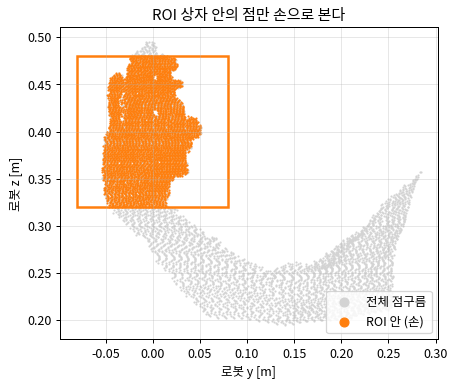

In [2]:
print('ROI 상자 최소 [m]:', rd.ROI_LOW, ' 최대 [m]:', rd.ROI_HIGH)
print('상자 크기 [m]:', (rd.ROI_HIGH - rd.ROI_LOW).round(3))

rec = rd.FRAMES[60]
d = rd.load_depth(rec)
pc, _, _ = rd.backproject(d)                 # 10 노트에서 만든 역투영
hand = rd.roi_points(d)
print(f'map_step {rec["map_step"]}: 전체 점 {len(pc)}개 중 ROI 안 점 {len(hand)}개')

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(pc[::10, 1], pc[::10, 2], s=0.5, c='lightgray', label='전체 점구름')
ax.scatter(hand[::5, 1], hand[::5, 2], s=0.5, c='tab:orange', label='ROI 안 (손)')
ax.add_patch(plt.Rectangle((rd.ROI_LOW[1], rd.ROI_LOW[2]), *(rd.ROI_HIGH - rd.ROI_LOW)[1:], fill=False, ec='tab:orange', lw=2))
ax.set_xlabel('로봇 y [m]'); ax.set_ylabel('로봇 z [m]'); ax.set_aspect('equal'); ax.legend(loc='lower right', markerscale=10)
ax.set_title('ROI 상자 안의 점만 손으로 본다')
plt.show()

**결과 해석:** 상자(16 cm × 16 cm × 16 cm) 안의 손바닥 점만 주황색으로 골라졌다. 상자 밖의 손목·팔뚝은 손 비용에 들어가지 않는다. 상자를 손으로 정했기 때문에 손이 상자를 벗어나면 그 부분은 놓친다. 이것이 이 방식의 한계 중 하나다.

## 3. 점이 너무 많다 — 20 mm 칸마다 대표점 하나

### 문제
ROI 안의 점은 수천 개다. 이 점을 모두 장애물로 넣으면, 후보 400개 × 시점 30개 × 충돌 구 61개마다 수천 개 점과의 거리를 재야 한다. 게다가 7절에서 보겠지만 cuRobo에 넣으려면 장애물 **개수가 고정**되어 있어야 한다.

### 아이디어
손 표면을 로봇 정면에서 본 y–z 평면에 20 mm 칸으로 나누고, **칸마다 대표점 하나**만 남긴다. 규칙은 이렇다.
1. 점이 12개 미만인 칸은 버린다. 깊이 노이즈로 생긴 몇 개 안 되는 점을 거르기 위해서다.
2. 칸 안 점들의 중앙값을 구하고, **중앙값에 가장 가까운 실제 관측점**을 대표점으로 고른다. 평균점은 표면 위에 없을 수 있지만, 실제 관측점은 항상 표면 위에 있다.

이 대표점을 **anchor**라고 부른다.

In [3]:
def pick_anchors(points, bin_m=0.02, min_points=12):
    bins = np.floor((points[:, 1:] - rd.ROI_LOW[1:]) / bin_m).astype(int)   # y, z 칸 번호
    groups = bins[:, 0] * 8 + bins[:, 1]                                       # 칸 하나에 번호 하나 (z 방향 8칸)
    anchors = []
    for key in sorted(set(groups)):
        g = points[groups == key]
        if len(g) < min_points:
            continue                                                           # 점이 적은 칸은 버림
        center = np.median(g, axis=0)
        anchors.append(g[np.argmin(np.linalg.norm(g - center, axis=1))])       # 중앙값에 가장 가까운 실제 점
    return np.asarray(anchors, np.float32).reshape(-1, 3)

cand = pick_anchors(hand)
print('ROI 점', len(hand), '개 → 대표점 후보', len(cand), '개')

ROI 점 26332 개 → 대표점 후보 40 개


### 실제 실행 기록과 비교
실험 실행 중 매 깊이 프레임의 anchor가 `evidence/*/patches-per-frame.jsonl`에 남아 있다. 우리가 고른 후보와 비교해 본다.

**예측해 보기:** 위 코드는 실험 코드(`target_margin.py`)와 같은 규칙이다. 기록된 anchor 개수는 우리 후보 개수와 같을까?

In [4]:
patches = {c: {r['step']: r for r in read_jsonl(EVIDENCE / c / 'patches-per-frame.jsonl')} for c in CONDITIONS}

rows = []
for r in rd.FRAMES:
    pts = rd.roi_points(rd.load_depth(r))
    cnd = pick_anchors(pts)
    logged = np.array(patches['LOW'][r['map_step']]['anchors']).reshape(-1, 3)
    err = np.linalg.norm(cnd[:, None] - logged[None], axis=-1).min(axis=0).max() if len(logged) else 0.0
    rows.append((r['map_step'], len(pts), patches['LOW'][r['map_step']]['roi_points'], len(cnd), len(logged), err))
rows = np.array(rows)
print('ROI 점 수가 기록과 같은 프레임:', int((rows[:, 1] == rows[:, 2]).sum()), '/', len(rows))
print('기록된 anchor가 모두 우리 후보 안에 있나:', bool((rows[:, 5] < 1e-4).all()), '(최대 오차 %.1e m)' % rows[:, 5].max())
print('우리 후보 개수 %d~%d개, 기록된 anchor %d~%d개' % (rows[:, 3].min(), rows[:, 3].max(), rows[:, 4].min(), rows[:, 4].max()))
same = all(patches['R'][s]['anchors'] == patches['LOW'][s]['anchors'] == patches['HIGH'][s]['anchors'] for s in patches['LOW'])
print('R / LOW / HIGH 세 조건의 anchor가 모든 프레임에서 같은가:', same)

ROI 점 수가 기록과 같은 프레임: 236 / 236
기록된 anchor가 모두 우리 후보 안에 있나: True (최대 오차 7.0e-06 m)
우리 후보 개수 37~44개, 기록된 anchor 10~35개
R / LOW / HIGH 세 조건의 anchor가 모든 프레임에서 같은가: True


**결과 해석:**
- ROI 점 개수가 236프레임 모두 기록과 같다. 역투영과 ROI 선택을 정확히 재현했다.
- 기록된 anchor는 모두 우리 후보 안에 있다. 그런데 **기록된 개수가 더 적다.** 실험 코드에는 단계가 하나 더 있기 때문이다. 10 노트의 sentinel 거르기다. 후보 위치에서 지도 거리값을 물어, "모름"(−100)이거나 표면에서 6 cm보다 먼 후보는 버린다(`target_margin.py:33-35`). 이 노트에는 지도가 없어서 그 단계를 생략했다.
- 세 조건의 anchor가 똑같다. 같은 깊이 기록을 재생했으니 손 표현은 조건마다 같고, 다른 것은 비용을 쓰느냐와 η뿐이다.

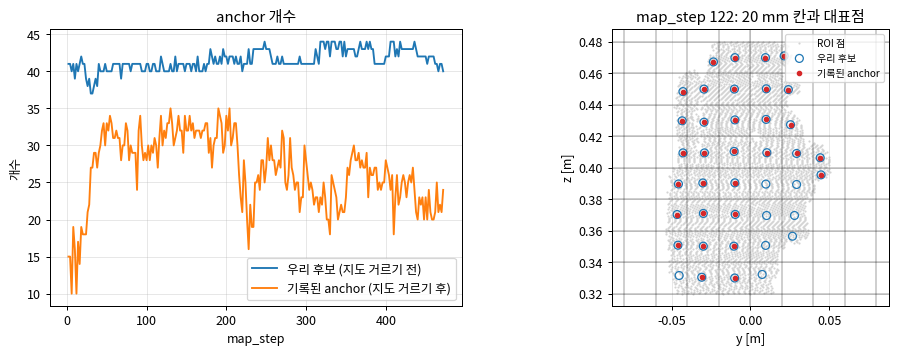

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(rows[:, 0], rows[:, 3], label='우리 후보 (지도 거르기 전)')
axs[0].plot(rows[:, 0], rows[:, 4], label='기록된 anchor (지도 거르기 후)')
axs[0].set_xlabel('map_step'); axs[0].set_ylabel('개수'); axs[0].legend(); axs[0].set_title('anchor 개수')

logged = np.array(patches['LOW'][rec['map_step']]['anchors'])
axs[1].scatter(hand[::5, 1], hand[::5, 2], s=0.5, c='lightgray', label='ROI 점')
axs[1].scatter(cand[:, 1], cand[:, 2], s=40, facecolors='none', edgecolors='tab:blue', label='우리 후보')
axs[1].scatter(logged[:, 1], logged[:, 2], s=12, c='tab:red', label='기록된 anchor')
for y in np.arange(rd.ROI_LOW[1], rd.ROI_HIGH[1] + 1e-9, 0.02):
    axs[1].axvline(y, color='k', lw=0.3)
for z in np.arange(rd.ROI_LOW[2], rd.ROI_HIGH[2] + 1e-9, 0.02):
    axs[1].axhline(z, color='k', lw=0.3)
axs[1].set_xlabel('y [m]'); axs[1].set_ylabel('z [m]'); axs[1].set_aspect('equal'); axs[1].legend(fontsize=8, loc='upper right')
axs[1].set_title(f'map_step {rec["map_step"]}: 20 mm 칸과 대표점')
plt.show()

**결과 해석:** 칸마다 대표점이 하나씩 있다(파란 원). 그중 지도 거르기를 통과한 것(빨간 점)만 실제 비용에 들어갔다. 후보는 프레임마다 37~44개로 거의 일정하지만, 거르기를 통과한 개수는 10~35개로 크게 바뀐다. **손 표면 일부가 비용에서 빠질 수 있다**는 뜻이다. 어느 후보가 왜 빠졌는지는 기록에 지도 거리값이 없어 이 노트에서는 확인할 수 없다.

**한 문장으로:** 대표점을 "평균점"이 아니라 "중앙값에 가장 가까운 실제 점"으로 고르는 이유를 설명해 보자.

## 4. 대표점을 장애물로 — 1 mm 조각과 거리

### 아이디어
대표점마다 한 변 1 mm인 아주 작은 정육면체 장애물을 놓는다. 사실상 점이다. 이렇게 하면 cuRobo가 원래 가지고 있는 "구와 상자 사이 충돌 비용" 계산을 그대로 쓸 수 있다. 장애물 조각을 담을 자리는 **최대 64개**를 미리 만들어 두고, 대표점 개수만큼만 켠다(7절에서 이유를 본다).

구와 조각 사이 간격은 08 노트와 같다. "점과 구 중심 거리 − 구 반지름"이다. 이 간격으로 η 비용을 계산한다.

### 실제 로봇 자세로 간격 다시 계산하기
`evidence/*/robot-spheres.npz`에는 매 스텝 실제 로봇 자세의 충돌 구 61개 `[x, y, z, r]`가 기록되어 있다. 이 반지름은 buffer 20 mm를 **포함**한 값이다(09 노트). 실험 로그의 간격(`original_surface_clearance_m`)은 "ROI 점(약 2,000개로 솎음)과 구 표면 사이 최솟값"이다. 같은 계산을 해서 로그와 맞는지 확인한다.

In [6]:
sph = {c: np.load(EVIDENCE / c / 'robot-spheres.npz')['spheres'] for c in CONDITIONS}
mets = {c: read_jsonl(EVIDENCE / c / 'metrics.jsonl') for c in CONDITIONS}
total = rd.META['total_steps']
by_step = {r['map_step']: r for r in rd.FRAMES}
frame_at, last = {}, None
for s in range(1, total + 1):                       # 각 스텝에서 쓰는 깊이 = 그 스텝까지의 가장 최근 프레임
    last = by_step.get(s, last); frame_at[s] = last

cache = {}
def eval_points(r):                                  # ROI 점을 약 2,000개로 솎음 (target_margin.py:23과 같음)
    if r['map_step'] not in cache:
        p = rd.roi_points(rd.load_depth(r)); cache[r['map_step']] = p[::max(1, len(p) // 2000)]
    return cache[r['map_step']]

def clearance(S, P):
    S = S[S[:, 3] > 0]
    return (np.linalg.norm(P[:, None] - S[None, :, :3], axis=-1) - S[None, :, 3]).min()

clear = {}
for c in CONDITIONS:
    mine = np.array([np.nan if frame_at[s] is None else clearance(sph[c][s - 1], eval_points(frame_at[s])) for s in range(1, total + 1)])
    logv = np.array([np.nan if m['original_surface_clearance_m'] is None else m['original_surface_clearance_m'] for m in mets[c]])
    ok = np.isfinite(mine) & np.isfinite(logv); i = np.nanargmin(mine); clear[c] = mine
    print(f'{c:4s} 로그와 최대 차이 {1000*np.abs(mine[ok]-logv[ok]).max():.4f} mm | 최소 간격 {1000*mine[i]:7.2f} mm (buffer 포함) @ step {i+1} | buffer 제외 {1000*mine[i]+20:7.2f} mm')

R    로그와 최대 차이 0.0000 mm | 최소 간격  -29.54 mm (buffer 포함) @ step 163 | buffer 제외   -9.54 mm
LOW  로그와 최대 차이 0.0000 mm | 최소 간격  -11.20 mm (buffer 포함) @ step 169 | buffer 제외    8.80 mm
HIGH 로그와 최대 차이 0.0000 mm | 최소 간격   40.43 mm (buffer 포함) @ step 165 | buffer 제외   60.43 mm


**결과 해석:** 다시 계산한 값이 로그와 같다. 최소 간격은 R −29.54 mm, LOW −11.20 mm, HIGH +40.43 mm(buffer 포함)다. 손 비용이 없는 R이 가장 깊이 겹쳤고, 손 비용이 있는 LOW·HIGH는 덜 겹치거나 떨어져서 지나갔다. 12 노트에서 이 결과를 자세히 읽는다.

## 5. 얼마나 멀리서부터 피할까 — 질량으로 η 정하기

### 문제
손 비용의 η를 얼마로 할까? η가 크면 손에서 멀리 떨어져 지나가지만 그만큼 돌아간다. 연구 질문은 이것이었다. **충돌했을 때 더 위험한 상황이면 더 일찍(더 먼 거리부터) 피하게 하자.**

### 아이디어 1: 충돌에서 "실제로 느끼는" 질량
로봇(질량 $m_r$)과 손(질량 $m_h$)이 부딪힐 때, 충돌에 쓰이는 운동 에너지는 두 질량을 따로 보지 않고 하나로 합친 값으로 정해진다.

$$
\mu = \frac{m_r\, m_h}{m_r + m_h},\qquad E_{\text{충돌}} = \tfrac12\,\mu\, v_{\text{상대}}^2
$$

이 $\mu$를 **환산질량**(reduced mass)이라고 한다. 이 프로젝트에서는 유효질량이라는 말과 같은 뜻으로 쓴다. 성질 두 가지를 알아 두면 된다.
- $\mu$는 두 질량 중 **가벼운 쪽보다 항상 작거나 같다.** 가벼운 쪽이 충돌을 좌우한다.
- 같은 상대 속도에서 $\mu$가 크면 충돌 에너지가 크다.

예를 들어 손만 움직이는 가벼운 상황(0.6 kg)보다 팔 전체가 함께 실린 무거운 상황(2.3 kg)에서 μ가 크다. 로봇 질량은 5 kg으로 **가정**했다.

m_h = 0.6 kg → μ = 0.5357 kg  (m_r = 5 kg 가정)
m_h = 2.3 kg → μ = 1.5753 kg  (m_r = 5 kg 가정)


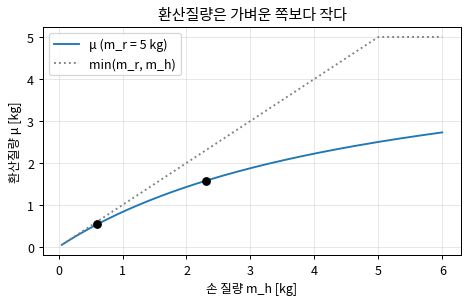

In [7]:
m_h = np.linspace(0.05, 6, 300)
for mh in [0.6, 2.3]:
    print(f'm_h = {mh} kg → μ = {reduced_mass(mh):.4f} kg  (m_r = 5 kg 가정)')

plt.figure(figsize=(6, 3.3))
plt.plot(m_h, reduced_mass(m_h), label='μ (m_r = 5 kg)')
plt.plot(m_h, np.minimum(m_h, 5.0), ':', color='gray', label='min(m_r, m_h)')
plt.scatter([0.6, 2.3], [reduced_mass(0.6), reduced_mass(2.3)], c='k', zorder=5)
plt.xlabel('손 질량 m_h [kg]'); plt.ylabel('환산질량 μ [kg]'); plt.legend()
plt.title('환산질량은 가벼운 쪽보다 작다')
plt.show()

### 아이디어 2: μ에 비례해 η를 키우기
가벼운 손(0.6 kg)을 기준으로 η = 25 mm로 정한다. 이 값은 기존 환경 비용의 η와 같다. μ가 기준보다 크면 η를 그 비율만큼 키운다.

$$
\eta(m_h; p) = 0.025 \left(\frac{\mu(m_h)}{\mu(0.6)}\right)^{p}\ [\text{m}]
$$

지수 $p$는 μ가 커질 때 η를 얼마나 가파르게 키울지 정한다. 처음 정책(`policy.py`)은 $p = 0.5$(제곱근)였다. 최종 실험은 차이를 더 뚜렷하게 보려고 $p = 1$을 썼다. 이를 민감도 설정이라고 부른다.

**예측해 보기:** 2.3 kg의 μ는 0.6 kg의 약 2.94배다. p = 1이면 η는 몇 mm일까? p = 0.5면?

In [8]:
print(f'μ 비율 = {reduced_mass(2.3) / reduced_mass(0.6):.4f}')
print(f'{"조건":6s} {"m_h[kg]":>8s} {"p":>4s} {"η [mm]":>8s}')
for name, mh in [('LOW', 0.6), ('HIGH', 2.3)]:
    for p in [0.5, 1.0]:
        print(f'{name:6s} {mh:8.1f} {p:4.1f} {1000 * eta_policy(mh, p):8.2f}')

for c in CONDITIONS:
    pol = json.loads((EVIDENCE / c / 'mass-policy.json').read_text(encoding='utf-8'))
    print(f'{c:4s} 실행 기록 η = {1000 * pol["eta_calculated_m"]:.2f} mm, 식: {pol["eta_formula"]}')

μ 비율 = 2.9406
조건      m_h[kg]    p   η [mm]
LOW         0.6  0.5    25.00
LOW         0.6  1.0    25.00
HIGH        2.3  0.5    42.87
HIGH        2.3  1.0    73.52
R    실행 기록 η = 25.00 mm, 식: 0.025*sqrt(mu(m_h)/mu(0.6))
LOW  실행 기록 η = 25.00 mm, 식: 0.025*sqrt(mu(m_h)/mu(0.6))
HIGH 실행 기록 η = 73.52 mm, 식: 0.025*(mu(m_h)/mu(0.6))**1


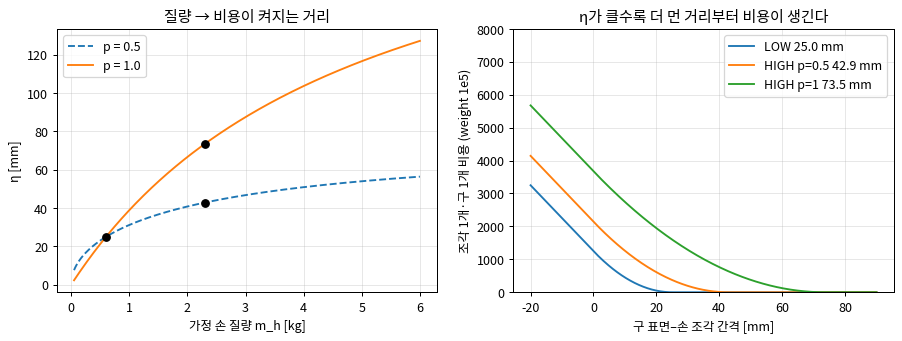

In [9]:
gap = np.linspace(-0.02, 0.09, 400)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for p, ls in [(0.5, '--'), (1.0, '-')]:
    axs[0].plot(m_h, 1000 * eta_policy(m_h, p), ls, label=f'p = {p}')
axs[0].scatter([0.6, 2.3, 2.3], [25, 1000 * eta_policy(2.3, 0.5), 1000 * eta_policy(2.3, 1.0)], c='k', zorder=5)
axs[0].set_xlabel('가정 손 질량 m_h [kg]'); axs[0].set_ylabel('η [mm]'); axs[0].legend(); axs[0].set_title('질량 → 비용이 켜지는 거리')
for name, eta in [('LOW 25.0 mm', 0.025), ('HIGH p=0.5 42.9 mm', eta_policy(2.3, 0.5)), ('HIGH p=1 73.5 mm', eta_policy(2.3, 1.0))]:
    axs[1].plot(1000 * gap, eta_cost(gap, eta, 1e5), label=name)
axs[1].set_xlabel('구 표면–손 조각 간격 [mm]'); axs[1].set_ylabel('조각 1개·구 1개 비용 (weight 1e5)')
axs[1].set_ylim(0, 8000); axs[1].legend(); axs[1].set_title('η가 클수록 더 먼 거리부터 비용이 생긴다')
plt.show()

**결과 해석:** p = 1이면 η = 25 × 2.94 ≈ 73.52 mm, p = 0.5면 25 × √2.94 ≈ 42.87 mm다. 실행 기록 값도 같다. 오른쪽 그림처럼 η가 크면 같은 간격에서 비용이 더 크고, 더 먼 거리부터 비용이 생긴다.

이 정책을 해석할 때 주의할 점이 있다.
- 질량은 **η를 정하는 데만** 쓴다. MPPI의 예측 모델에는 질량이 들어가지 않는다(01·09 노트: rollout은 가속도 적분).
- 로봇 5 kg, 손 0.6/2.3 kg은 측정값이 아니라 **가정값**이다. Franka의 실제 유효질량을 계산한 것도 아니다.
- 식은 충돌 에너지 관계에서 착안한 **휴리스틱**이다. 물리적으로 유도한 안전거리가 아니다. η는 비용이 켜지는 거리일 뿐 그만큼 떨어진다는 **보장이 아니다**(4절 결과: HIGH의 최소 간격 40.4 mm < η 73.5 mm).

**한 문장으로:** "η = 73.5 mm이면 손과 최소 73.5 mm 떨어진다"는 말이 왜 틀렸는지 설명해 보자.

## 6. 비용에 항 하나 더하기

### 아이디어
02 노트에서 비용은 **여러 항의 합**이었다(목표 + 입력 크기 + 장애물 …). 손 비용도 항 하나를 더하는 것뿐이다.

$$
C_{\text{전체}} = C_{\text{기존}} + \alpha\, C_{\text{손}}
$$

- $C_{\text{기존}}$: 목표 추종, 관절 한계, 자체 충돌, 지도(nvblox) 충돌 등 원래 비용 전부.
- $C_{\text{손}}$: 손 조각들과 충돌 구 사이의 η 비용 합. weight는 환경 충돌과 같은 100000.
- $\alpha$: 손 비용을 켜고 끄는 배율. 조건 R은 0, LOW·HIGH는 1.

### 2D로 확인하기
06 노트의 2D 점 장면으로 실험 상황을 흉내 낸다. 지도에는 손이 **보이지 않는다**고 가정한다(기존 비용에 장애물 없음, 10 노트의 "모름" 구멍). 손 비용 항만 조건별로 다르게 한다.
- R: α = 0 (손 비용 없음)
- LOW: α = 1, η = 25 mm
- HIGH: α = 1, η = 73.5 mm

MPPI는 05~06 노트의 `mppi_step`을 그대로 쓴다.

In [10]:
GOAL = np.array([1.0, 0.0])
HAND = [((0.5, 0.02), 0.06)]          # 손 (지도에는 안 보인다고 가정)
R_ROBOT, DT2 = 0.05, 0.05

def run_condition(alpha, eta_hand, steps=80, K=200, T=30, iters=3, seed=0):
    rng = np.random.default_rng(seed)
    p, v = np.zeros(2), np.zeros(2)
    mu, sigma = np.zeros((T, 2)), np.full(2, 2.0)
    traj = [p]
    for _ in range(steps):
        def total_cost(U):
            P, V = point_rollout(p, v, U, DT2)
            base = point_cost(P, V, U, GOAL, [])                                    # C_기존: 지도엔 손이 없음
            hand = (100.0 * eta_cost(obstacle_gap(P[..., 1:, :], HAND, R_ROBOT), eta_hand)).sum(-1)   # C_손
            return base + alpha * hand                                              # C_전체 = C_기존 + α C_손
        for _ in range(iters):
            mu, sigma, info = mppi_step(mu, sigma, total_cost, K, 1.0, rng, u_max=4.0)
        a = info['best'][0]
        p, v = p + v * DT2 + 0.5 * a * DT2 ** 2, v + a * DT2
        traj.append(p)
        mu = np.concatenate([mu[1:], mu[-1:]])                                      # warm start
    return np.array(traj)

**예측해 보기:** 세 조건의 최소 간격은 어떤 순서일까? 최소 간격이 η와 같아질까?

R    α=0, η= 25.0 mm → 최소 간격  -45.3 mm
LOW  α=1, η= 25.0 mm → 최소 간격   18.8 mm
HIGH α=1, η= 73.5 mm → 최소 간격   67.7 mm


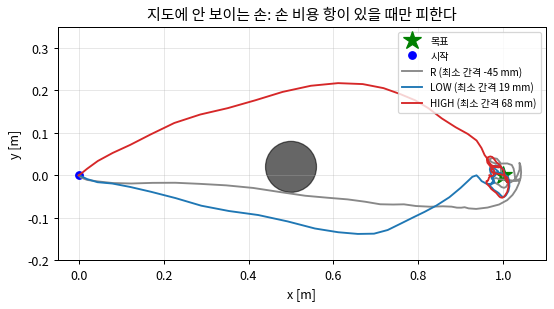

In [11]:
conds = {'R': (0, 0.025), 'LOW': (1, 0.025), 'HIGH': (1, eta_policy(2.3, 1.0))}
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_scene_2d(ax, GOAL, HAND, R_ROBOT, start=(0, 0), lim=((-0.05, 1.1), (-0.2, 0.35)))
for name, (alpha, eta_h) in conds.items():
    tr = run_condition(alpha, eta_h)
    gmin = obstacle_gap(tr, HAND, R_ROBOT).min()
    print(f'{name:4s} α={alpha}, η={1000*eta_h:5.1f} mm → 최소 간격 {1000*gmin:6.1f} mm')
    ax.plot(*tr.T, color=COLORS[name], label=f'{name} (최소 간격 {1000*gmin:.0f} mm)')
ax.legend(fontsize=8, loc='upper right'); ax.set_title('지도에 안 보이는 손: 손 비용 항이 있을 때만 피한다')
plt.show()

**결과 해석:**
- 선은 로봇 **중심**의 경로이고, 로봇 반지름 5 cm는 그리지 않았다. 그래서 R의 선이 손 원 바로 아래를 지나도 실제로는 겹친다.
- R은 손 비용이 없어 손과 겹친 채 지나간다(간격 −45 mm). 실험의 Baseline과 같은 상황이다.
- LOW는 손 비용이 생겨 비켜 가고, HIGH는 η가 커서 더 멀리 돌아간다.
- 최소 간격은 R < LOW < HIGH 순서지만 **η보다 작다.** soft cost는 목표 비용과의 절충이라서 η 안으로 조금 들어가는 것이 전체 비용으로는 더 싸기 때문이다. 실험에서도 같았다.

이 결과는 seed 하나, 토이 장면 하나의 결과다. 경향을 보는 용도로만 쓴다.

**직접 해보기:** `HAND`의 y 위치를 0.02에서 0.10으로 바꿔 보자. 손이 경로에서 비켜나 있으면 어떻게 될까?
<details><summary>예상 결과</summary>

직선 경로가 손에서 η보다 멀어지면 손 비용이 0이라 세 조건이 거의 같은 경로로 간다. 손 비용은 η 안으로 들어올 때만 행동을 바꾼다.
</details>

## 7. cuRobo에 끼워 넣기 — 고정 크기 64칸

### 문제 1: cuRobo의 비용 함수를 어떻게 바꾸나
cuRobo 안에는 후보마다 비용을 계산하는 함수(`cost_fn`)가 이미 있다. 라이브러리 코드를 고치지 않고 손 비용을 더하고 싶다.

### 아이디어 1
원래 함수를 변수에 보관해 두고, "원래 함수 결과 + α × 손 비용"을 돌려주는 새 함수를 만들어 **그 자리에 바꿔 끼운다.** 파이썬에서는 객체의 메서드를 실행 중에 바꿀 수 있다(`types.MethodType`). 실제 코드는 다음과 같다.

In [12]:
show_code(REPO / 'experiment/base_target_cost.py', 29, 36, width=130)

   29|             original=opt.rollout_fn.cost_fn
   30|             if condition!='R':
   31|                 def hooked(rollout,state,action_batch=None,_old=original,_cost=cost,_snap=snap):
   32|                     base=_old(state,action_batch);target=_cost.forward(state.robot_spheres)
   33|                     scaled=self.alpha*target;total=base+scaled
   34|                     _snap['base'].copy_(base);_snap['target'].copy_(target);_snap['scaled'].copy_(scaled);_snap['total'].copy_(tot ...
   35|                     return total
   36|                 opt.rollout_fn.cost_fn=types.MethodType(hooked,opt.rollout_fn)


읽는 법:
- `:29` `original = opt.rollout_fn.cost_fn`: 원래 비용 함수를 보관한다.
- `:30` `if condition != 'R'`: R이면 바꾸지 않는다. R은 α = 0과 같다.
- `:32-33` `base = _old(...)`, `target = _cost.forward(state.robot_spheres)`, `total = base + alpha * target`: 6절의 식 그대로다. `_cost`는 cuRobo의 원래 "구–상자 충돌 비용"을 복사하되 장애물 목록만 손 조각 64칸으로 바꾼 객체다.
- `:36` 새 함수를 MPPI optimizer 안의 `cost_fn` 자리에 끼운다.

### 문제 2: 왜 64칸을 미리 만들어 두나
cuRobo는 빠르게 돌기 위해 **CUDA graph**라는 기능을 쓴다. 처음 한 번 GPU 계산 순서를 "녹화"해 두고, 이후에는 녹화를 재생만 한다. 매번 파이썬이 GPU에 명령을 하나씩 보내는 것보다 훨씬 빠르다.

대신 제약이 있다. 녹화는 **녹화할 때 쓰던 메모리 위치**를 그대로 기억한다.
- 녹화한 뒤에 비용 함수를 바꿔 끼워도 반영되지 않는다. 그래서 바꿔 끼우기는 반드시 녹화 **전**에 한다(`assert not opt.cu_opt_init`).
- 손 조각 개수가 프레임마다 바뀐다고 새 배열을 만들면, 녹화는 옛 배열을 계속 읽는다.

그래서 조각 자리 64칸을 처음에 만들어 두고, 매 프레임 **같은 배열 안의 값**(위치, 켜짐/꺼짐)만 바꾼다. 대표점이 25개면 25칸만 켜고 나머지 39칸은 끈다.

아래는 녹화를 흉내 낸 작은 예다. "녹화"가 배열 객체를 붙잡아 두고, 재생할 때 그 배열을 읽는다.

In [13]:
slots = np.full((4, 2), 10.0)           # 손 조각 자리 4칸 (멀리 둔 = 꺼짐)
enabled = np.zeros(4)

def hand_cost_of(state, slot_arr, en_arr, eta=0.5):
    d = np.linalg.norm(state[:, None] - slot_arr[None], axis=-1)
    return (en_arr * eta_cost(d, eta)).sum(-1)

class Recording:                         # CUDA graph 흉내: 녹화 시점의 배열 객체를 붙잡아 둔다
    def __init__(self, fn, *arrays):
        self.fn, self.arrays = fn, arrays
    def replay(self, state):
        return self.fn(state, *self.arrays)

rec_graph = Recording(hand_cost_of, slots, enabled)
state = np.array([[1.0, 0.0], [0.0, 1.0]])
print('조각 없음             :', rec_graph.replay(state))

slots[0] = [1.2, 0.0]; enabled[0] = 1.0                  # 같은 배열 안의 값을 바꿈 (올바른 방법)
print('같은 배열 값 바꾸기 후 :', rec_graph.replay(state))

slots = np.array([[0.0, 1.2]] + [[10.0, 10.0]] * 3)      # 새 배열을 만듦 (잘못된 방법)
enabled = np.array([1.0, 0, 0, 0])
print('새 배열을 만든 뒤      :', rec_graph.replay(state), '← 녹화는 옛 배열을 계속 읽는다')

조각 없음             : [0. 0.]
같은 배열 값 바꾸기 후 : [0.09 0.  ]
새 배열을 만든 뒤      : [0.09 0.  ] ← 녹화는 옛 배열을 계속 읽는다


**결과 해석:** 같은 배열 안의 값을 바꾸면 재생 결과에 바로 반영된다(첫 번째 상태에 비용이 생김). 새 배열을 만들면 이름은 새 배열을 가리키지만, 녹화는 옛 배열을 붙잡고 있어서 결과가 그대로다. 실제 코드도 매 갱신마다 메모리 주소가 그대로인지 검사한다(`base_target_cost.py`의 `assert self.pointers()==self.addresses`). η를 바꿀 때도 `activation_distance.fill_(...)`로 같은 텐서의 값만 바꾼다(`hand_experiment.py:109`).

## 8. feasible은 손 비용을 보지 않는다

### 문제
cuRobo의 결과에는 `feasible`(실행 가능) 표시가 있다. 손과 부딪힐 것 같으면 이 표시가 False가 되어 로봇이 멈출까?

In [14]:
for c in CONDITIONS:
    feas = np.array([all(m['feasible']) for m in mets[c]])
    neg = np.array([m['original_surface_clearance_m'] is not None and m['original_surface_clearance_m'] < 0 for m in mets[c]])
    print(f'{c:4s} feasible=False 스텝 {(~feas).sum():3d}개 | 간격<0 (buffer 포함) 스텝 {neg.sum():3d}개, 그중 feasible=True {int((neg & feas).sum())}개')
conn = json.loads((EVIDENCE / 'LOW' / 'cost-connection.json').read_text(encoding='utf-8'))
print('\n실행 기록의 설명:', conn['aux_and_safety_costs'])

R    feasible=False 스텝   0개 | 간격<0 (buffer 포함) 스텝   7개, 그중 feasible=True 7개
LOW  feasible=False 스텝   0개 | 간격<0 (buffer 포함) 스텝  11개, 그중 feasible=True 11개
HIGH feasible=False 스텝   0개 | 간격<0 (buffer 포함) 스텝   0개, 그중 feasible=True 0개

실행 기록의 설명: unchanged; reported constraints do not include target penalty


**결과 해석:** 세 조건 모두 `feasible=False`는 한 번도 없다. 구가 손 관측면과 겹친 스텝에서도 True다. feasible은 관절 한계 같은 **제약 검사** 결과이고, 손 비용은 들어가지 않는다. 실행 기록도 "보고된 제약에는 손 비용이 포함되지 않는다"고 적고 있다.

즉 손 비용은 순수한 **soft cost**다(06 노트). 모든 후보가 손에 가까워도 MPPI는 그중 비용이 가장 낮은 후보를 골라 실행한다. 멈추는 로직은 feasible=False일 때만 작동한다.

## 9. 세 조건을 정리하면

| 조건 | 손 표현 | 손 비용 α | 손 η | 비교의 의미 |
|---|---|---|---|---|
| R (Baseline) | 없음 (지도만) | 0 | — | 기준 |
| LOW (0.6 kg) | ROI 조각 | 1 | 25 mm | R → LOW: 손 표현 추가 + 비용 추가 |
| HIGH (2.3 kg, p=1) | ROI 조각 (LOW와 같음) | 1 | 73.52 mm | LOW → HIGH: **η만** 바뀜 |

**R → LOW**의 차이에는 두 가지가 섞여 있다. 질량 정책 효과와, 지도의 "모름" 구멍을 손 조각이 메운 **표현 효과**다. 질량 가정의 효과만 보려면 같은 손 표현에서 η만 바뀐 **LOW → HIGH**를 비교해야 한다.

R 실행 기록에도 손 비용 값(`target_cost_current`)이 있다. R에서도 비교를 위해 η = 25 mm로 현재 자세의 손 비용을 **계산만 해서 기록**했고, MPPI에는 더하지 않았다. 아래에서 그 값을 본다.

In [15]:
r_cost = np.array([m['target_cost_current'] for m in mets['R']])
print('R step 163 (가장 깊이 겹친 순간)의 기록된 손 비용 (η=25 mm, 계산만 함): %.1f' % r_cost[162])
import csv
diag = next(r for r in csv.DictReader(open(REPO / 'docs/data/R-nvblox-nearest.csv', encoding='utf-8')) if int(float(r['step'])) == 163)
print('같은 자세를 η=73.5 mm로 계산한 진단값 (docs/data/R-nvblox-nearest.csv): %.1f' % float(diag['roi_high_p1_cost']))
print('R의 rollout 비용 함수에 연결되었나:', json.loads((EVIDENCE / 'R' / 'cost-connection.json').read_text(encoding='utf-8'))['optimizers'][0]['connected'])

R step 163 (가장 깊이 겹친 순간)의 기록된 손 비용 (η=25 mm, 계산만 함): 18502.6
같은 자세를 η=73.5 mm로 계산한 진단값 (docs/data/R-nvblox-nearest.csv): 217650.1
R의 rollout 비용 함수에 연결되었나: False


**결과 해석:** R step 163의 기록값 18,502.6은 "R의 자세를 LOW 방식으로 평가했다면 이만큼"이라는 진단값이다. 이 값을 따로 돌린 실험 결과로 읽으면 안 된다. R에서는 rollout 비용 함수에 연결되지 않았다(`connected: False`).

## 핵심 정리

- 지도의 "모름" 구멍을 피하려고 **ROI 안 손 관측점**을 직접 장애물로 넣는다.
- 점이 많으니 y–z 20 mm 칸마다 **대표점(anchor)** 하나만 남긴다(12점 이상, 중앙값에 가장 가까운 실제 점). 지도에서 "모름"이거나 표면에서 먼 후보는 버리고, 최대 64개 1 mm 조각으로 넣는다.
- 손 η는 가정 질량의 **환산질량 μ**로 정한다: $\eta = 0.025\,(\mu/\mu(0.6))^p$. LOW 25 mm, HIGH 42.87 mm(p=0.5) / 73.52 mm(p=1). 휴리스틱이며 안전거리 보장이 아니다.
- 비용은 **항 하나를 더할 뿐**이다: $C_{\text{전체}} = C_{\text{기존}} + \alpha C_{\text{손}}$. cuRobo의 `cost_fn`을 CUDA graph 녹화 **전에** 바꿔 끼우고, 조각 자리는 64칸 고정 배열의 값만 바꾼다.
- `feasible`은 손 비용을 보지 않는다. 손 비용은 soft cost다.

## 확인 문제

<details><summary>1. ROI 방식이 10 노트의 "구 중심이 모름이면 비용 0" 문제를 피하는 이유는?</summary>

손 관측점을 장애물 조각으로 직접 넣고 구와 조각 사이 거리를 계산한다. 구 중심 위치의 지도 상태와 상관없이 거리가 나온다.
</details>

<details><summary>2. ROI 방식으로도 여전히 놓치는 부분은?</summary>

ROI 상자 밖의 손·팔, 카메라에 보이지 않는 손 뒷면, 지도 거르기에서 빠진 대표점, 12점 미만이라 버려진 칸이다.
</details>

<details><summary>3. m_r = 5 kg일 때 m_h = 1.0 kg의 μ는? p = 1이면 η는?</summary>

μ = 5×1/6 ≈ 0.833 kg. μ(0.6) ≈ 0.536 kg이므로 비율 ≈ 1.556, η ≈ 25 × 1.556 ≈ 38.9 mm.
</details>

<details><summary>4. 손 비용 함수를 CUDA graph 녹화가 끝난 뒤에 바꿔 끼우면 어떻게 되나?</summary>

녹화된 GPU 계산 순서만 재생되므로 새 함수가 호출되지 않는다. 손 비용이 반영되지 않는다.
</details>

<details><summary>5. HIGH가 LOW보다 손에서 멀리 지나갔다. 이 차이를 "질량 가정의 효과"라고 부를 수 있는 이유는?</summary>

두 조건은 손 표현(대표점, 조각)과 다른 설정이 모두 같고 η만 다르다. 그래서 차이를 η, 즉 질량 가정에서 나온 값의 차이로 돌릴 수 있다. 단, 단일 장면·단일 seed 결과다.
</details>

## 실제 프로젝트에서는

| 이 노트 | 프로젝트 파일 |
|---|---|
| ROI 상자, 칸 크기, 최소 점 수, 슬롯 64, 조각 1 mm | `experiment/target.json` |
| 역투영 → ROI → 대표점 → 지도 거르기 | `experiment/target_margin.py:19-35` |
| 질량 → η (p = 0.5) | `experiment/policy.py` |
| p = 1 민감도 설정 | `experiment/hand_experiment.py:104-111` (`--eta-exponent 1.0`, `scripts/replay.sh HIGH`) |
| 손 비용 객체, cost_fn 바꿔 끼우기, 64칸 갱신 | `experiment/base_target_cost.py:11-46`, `update()` |
| 매 깊이 프레임마다 대표점 갱신 → 조각 갱신 | `hand_experiment.py:246` `observer.update(...)` → `channel.update(observer.anchors)` |
| 실행 기록 | `evidence/*/patches-per-frame.jsonl`, `mass-policy.json`, `cost-connection.json` |

## 다음 노트

[12 · 실험 결과 읽기](12_results_analysis.ipynb): 손 비용과 η가 실제 Franka의 움직임을 어떻게 바꿨는지, R/LOW/HIGH 실행 기록으로 이격·경로·도달 시간을 읽는다.